# 02. Model comparison
Compare the Linear Regression baseline with Random Forest on the same train/test split.

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.metrics import evaluate
from src.split import load_split

X_train, X_test, y_train, y_test = load_split()

## Train both models and compare test metrics

In [2]:
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42),
}
for m in models.values():
    m.fit(X_train, y_train)

results = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in models.items()}).T
results.round(3)

,MAE,RMSE,R2
Linear Regression,0.533,0.746,0.576
Random Forest,0.327,0.504,0.806


## Cross-validation (5-fold, RMSE)
A single split can be lucky; cross-validation checks the result is stable.

In [3]:
from sklearn.model_selection import cross_val_score

cv = {name: -cross_val_score(m, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)
      for name, m in models.items()}
pd.DataFrame(cv).agg(["mean", "std"]).round(3)

,Linear Regression,Random Forest
mean,0.721,0.510
std,0.011,0.006


## Predicted vs actual

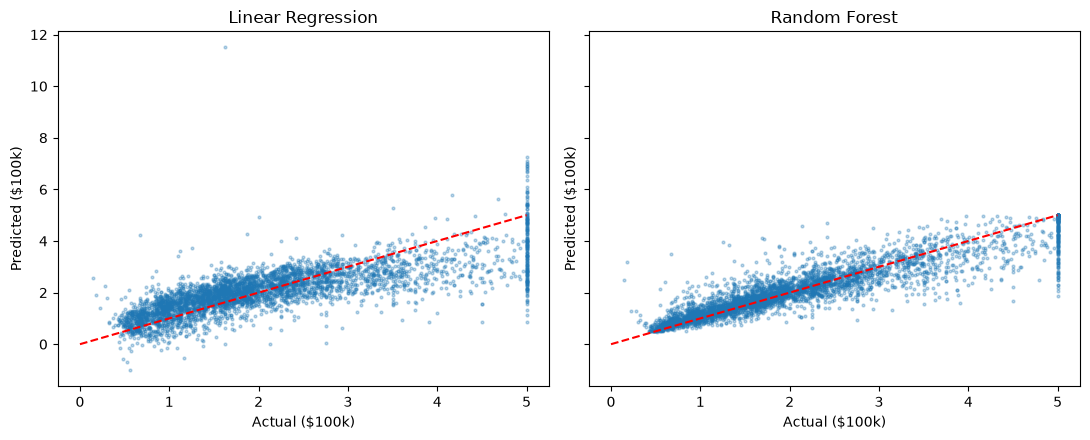

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, (name, m) in zip(axes, models.items()):
    ax.scatter(y_test, m.predict(X_test), s=4, alpha=0.3)
    ax.plot([0, 5], [0, 5], "r--")
    ax.set(title=name, xlabel="Actual ($100k)", ylabel="Predicted ($100k)")
plt.tight_layout()
plt.show()

## Feature importance (Random Forest)

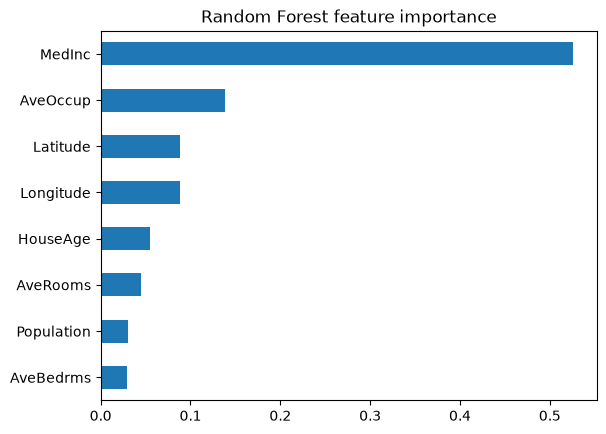

MedInc        0.526
AveOccup      0.138
Latitude      0.089
Longitude     0.088
HouseAge      0.054
AveRooms      0.044
Population    0.031
AveBedrms     0.030
dtype: float64

In [5]:
imp = pd.Series(models["Random Forest"].feature_importances_, index=X_train.columns).sort_values()
imp.plot.barh()
plt.title("Random Forest feature importance")
plt.show()
imp.sort_values(ascending=False).round(3)

## Conclusions
- Random Forest beats the baseline: test RMSE 0.504 vs 0.746 (about 32% lower) and R2 0.806 vs 0.576.
- 5-fold CV agrees (RMSE 0.510 vs 0.721) with low variance, so the gain is not a lucky split.
- Random Forest overfits somewhat (train RMSE 0.186 vs test 0.504); limiting tree depth or tuning hyperparameters is the natural next step.
- Both models underpredict the capped $500k districts (see the predicted-vs-actual plot).
- `MedInc` dominates importance (0.53); location (Latitude/Longitude) and `AveOccup` come next.